# Final Team Project: Multi-Agent Financial Analysis System

### Team Members

* **Moinuddin K**
* **Ravisha Krishnamurthy**
* **Priya**

### GitHub Repository

[MS_AAI_520_GRP3](https://github.com/moinuddinghouse/MS_AAI_520_GRP3)

### Project Overview

This project presents a Multi-Agent Financial Analysis System designed to perform autonomous investment research. The system combines specialized agents, dynamic tool use, workflow orchestration, self-reflection, and learning across runs to analyze financial market information and generate evidence-based investment insights.



### Required capabilities demonstrated

- Planning
- Dynamic tool use
- Self-reflection
- Learning across runs

### Required workflow patterns demonstrated

- Prompt Chaining
- Routing
- Evaluator–Optimizer


## 2. Environment Setup

The project uses Python libraries for financial data retrieval, data processing, visualization, and machine-learning utilities. The first cells install and import the required dependencies.

Running the installation cell once is sufficient for a fresh environment. After installation, the notebook can be executed from top to bottom.


In [1]:

%pip install -q yfinance pandas numpy matplotlib seaborn scikit-learn python-dateutil


Note: you may need to restart the kernel to use updated packages.


### Environment Setup — Explanation

The installation prepares the notebook for reproducible execution. `yfinance` is used for financial and market information, while pandas/numpy support data processing and matplotlib/seaborn support visualization.

If the environment is already configured, the installation cell may report that packages are already satisfied; that is expected.


In [2]:

import os
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("Environment ready.")


Environment ready.


### Imports — Explanation

The import cell loads the libraries used throughout the project. It also configures pandas display options so that intermediate agent outputs and evaluation tables remain readable.


## 3. Project Configuration

The selected stock ticker and analysis period are configured here. `AAPL` is used as the demonstration company, but the same workflow can be reused with another supported ticker.

The memory filename is also defined here so that learning information persists across notebook executions.


In [3]:

TICKER = "AAPL"
PERIOD = "6mo"
MEMORY_FILE = Path("investment_agent_memory.json")

# IMPORTANT: replace with your team's real repository before submission.
GITHUB_REPO = "https://github.com/moinuddinghouse/MS_AAI_520_GRP3"
print("Ticker:", TICKER)
print("GitHub:", GITHUB_REPO)


Ticker: AAPL
GitHub: https://github.com/moinuddinghouse/MS_AAI_520_GRP3


### Configuration — Interpretation

The configuration separates project parameters from implementation logic. This makes the notebook easier to reuse and allows the same agents to analyze another company by changing only the ticker.


## 4. Agent Architecture and Base Components

The system uses specialized agents instead of one large function. The base agent provides common behavior such as naming and logging, while specialized agents implement specific responsibilities.

The main deterministic agents are:

- **Research Manager:** creates the research plan.
- **Market Specialist:** analyzes prices, returns, volatility, and moving averages.
- **Earnings Specialist:** retrieves company-level financial information.
- **News Specialist:** ingests, preprocesses, classifies, extracts topics, and summarizes news.
- **Evaluator:** checks analysis completeness.
- **Optimizer:** improves the analysis using evaluator feedback.

Gemini is added later as the LLM reasoning layer.


In [4]:

class BaseAgent:
    def __init__(self, name):
        self.name = name

    def log(self, message):
        print(f"[{self.name}] {message}")


class ResearchManagerAgent(BaseAgent):
    def plan(self, ticker):
        self.log(f"Creating research plan for {ticker}")
        return [
            {"step": 1, "task": "Collect market price history", "tool": "Yahoo Finance"},
            {"step": 2, "task": "Collect company financial information", "tool": "Yahoo Finance"},
            {"step": 3, "task": "Collect recent financial news", "tool": "Yahoo Finance news"},
            {"step": 4, "task": "Route content to specialist agents", "tool": "Router"},
            {"step": 5, "task": "Generate integrated research analysis", "tool": "Analysis"},
            {"step": 6, "task": "Evaluate and refine the analysis", "tool": "Evaluator/Optimizer"},
            {"step": 7, "task": "Store a learning note", "tool": "Memory"},
        ]


class MarketSpecialistAgent(BaseAgent):
    def analyze_article(self, article):
        """Interpret a market-related article; this does not replace price indicators."""
        title = str(article.get("title", ""))
        text = str(article.get("text", article.get("summary", "")))
        return (
            f"Market Specialist reviewed: {title}. "
            "Treat the article as qualitative context and verify its implications "
            "against the independently retrieved price history and technical indicators. "
            f"Article context: {text[:350]}"
        )

    def analyze(self, history):
        self.log("Analyzing market data")
        if history.empty:
            return {"error": "No market data available."}

        close = history["Close"].dropna()
        returns = close.pct_change().dropna()

        ma20 = close.rolling(20).mean().iloc[-1] if len(close) >= 20 else None
        ma50 = close.rolling(50).mean().iloc[-1] if len(close) >= 50 else None

        result = {
            "start_price": float(close.iloc[0]),
            "latest_price": float(close.iloc[-1]),
            "period_return_pct": float((close.iloc[-1] / close.iloc[0] - 1) * 100),
            "annualized_volatility_pct": float(returns.std() * np.sqrt(252) * 100),
            "ma20": float(ma20) if pd.notna(ma20) else None,
            "ma50": float(ma50) if pd.notna(ma50) else None,
            "max_price": float(close.max()),
            "min_price": float(close.min()),
        }

        result["trend_signal"] = (
            "Bullish" if ma20 is not None and result["latest_price"] > result["ma20"]
            else "Bearish" if ma20 is not None
            else "Insufficient data"
        )
        return result


class EarningsSpecialistAgent(BaseAgent):
    def analyze_article(self, article):
        """Interpret an earnings-related article using an earnings-focused persona."""
        title = str(article.get("title", ""))
        text = str(article.get("text", article.get("summary", "")))
        keywords = [term for term in ["revenue", "profit", "earnings", "EPS", "guidance", "margin", "quarter"]
                    if term.lower() in (title + " " + text).lower()]
        evidence = ", ".join(keywords) if keywords else "no explicit earnings metric detected"
        return (
            f"Earnings Specialist reviewed: {title}. Relevant indicators: {evidence}. "
            "Confirm any reported figures against company filings or verified financial statements. "
            f"Article context: {text[:350]}"
        )

    def analyze(self, ticker):
        self.log("Analyzing company financial information")
        stock = yf.Ticker(ticker)

        try:
            info = stock.info
        except Exception as exc:
            self.log(f"Company information unavailable: {exc}")
            info = {}

        keys = [
            "longName", "sector", "industry", "marketCap",
            "trailingPE", "forwardPE", "profitMargins",
            "returnOnEquity", "debtToEquity", "revenueGrowth"
        ]
        return {key: info.get(key) for key in keys}


class NewsSpecialistAgent(BaseAgent):
    def analyze_article(self, article):
        """Analyze general financial news with a distinct news/sentiment persona."""
        title = str(article.get("title", ""))
        text = str(article.get("text", article.get("summary", "")))
        combined = (title + " " + text).lower()
        positive_terms = ["growth", "beats", "surge", "record", "expands", "partnership"]
        negative_terms = ["decline", "loss", "lawsuit", "cuts", "misses", "risk"]
        pos = sum(term in combined for term in positive_terms)
        neg = sum(term in combined for term in negative_terms)
        sentiment = "positive-leaning" if pos > neg else "negative-leaning" if neg > pos else "mixed/neutral"
        return (
            f"News Specialist reviewed: {title}. Preliminary keyword-based tone: {sentiment}. "
            "This is a lightweight heuristic, not a validated sentiment model. "
            f"Article context: {text[:350]}"
        )

    def ingest(self, ticker):
        self.log("Collecting recent news")
        try:
            raw = yf.Ticker(ticker).news
        except Exception as exc:
            self.log(f"News unavailable: {exc}")
            raw = []

        rows = []
        for item in raw[:20]:
            content = item.get("content", item)

            title = content.get("title") or item.get("title") or ""
            summary = content.get("summary") or item.get("summary") or ""

            provider = content.get("provider", {})
            publisher = provider.get("displayName", "") if isinstance(provider, dict) else item.get("publisher", "")

            canonical = content.get("canonicalUrl", {})
            link = canonical.get("url", "") if isinstance(canonical, dict) else item.get("link", "")

            rows.append({
                "title": title,
                "publisher": publisher,
                "summary": summary,
                "link": link,
                "published": content.get("pubDate", item.get("providerPublishTime", "")),
                "source_type": "live Yahoo Finance news",
                "is_live": True,
            })

        return pd.DataFrame(rows)

    def preprocess(self, news_df):
        self.log("Preprocessing news")
        if news_df.empty:
            return news_df

        df = news_df.copy()
        df["text"] = (df["title"].fillna("") + " " + df["summary"].fillna("")).str.strip()
        df["clean_text"] = (
            df["text"]
            .str.lower()
            .str.replace(r"http\S+", " ", regex=True)
            .str.replace(r"[^a-z0-9\s$%.-]", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )
        return df

    def classify(self, text):
        text = text.lower()
        groups = {
            "earnings": ["earnings", "revenue", "profit", "eps", "quarter", "guidance"],
            "market": ["stock", "shares", "price", "market", "rally", "selloff", "upgrade", "downgrade"],
            "news": ["acquisition", "launch", "partnership", "lawsuit", "regulator", "product", "ai"],
        }
        scores = {name: sum(term in text for term in terms) for name, terms in groups.items()}
        return max(scores, key=scores.get) if max(scores.values()) else "news"

    def extract(self, text):
        text = text.lower()
        topics = []
        groups = {
            "earnings": ["earnings", "revenue", "profit", "eps", "guidance"],
            "market": ["stock", "shares", "price", "market", "rally", "selloff"],
            "growth": ["growth", "expansion", "launch", "demand"],
            "risk": ["risk", "lawsuit", "regulator", "competition", "decline"],
        }
        for topic, terms in groups.items():
            if any(term in text for term in terms):
                topics.append(topic)
        return topics or ["general"]

    def summarize(self, df):
        self.log("Summarizing news")
        if df.empty:
            return "No recent live news was available from the selected source."

        lines = [f"- {row['title']} ({row.get('publisher', 'Unknown publisher')})"
                 for _, row in df.head(5).iterrows()]
        if "is_live" in df.columns and not bool(df["is_live"].fillna(False).any()):
            return "ILLUSTRATIVE SAMPLE ARTICLES — NOT LIVE NEWS; excluded from evidence scoring.\n" + "\n".join(lines)
        return "\n".join(lines)


# These explicitly hypothetical records allow the routing code to be demonstrated
# when a live news API returns no articles. They must never be treated as real news.
def illustrative_news_examples(ticker):
    return pd.DataFrame([
        {"title": f"Illustrative example: {ticker} quarterly revenue and earnings guidance", 
         "publisher": "Synthetic teaching example", "summary": "Hypothetical example mentioning revenue, profit, EPS and quarterly guidance.",
         "link": "", "published": "not a real publication date", "source_type": "illustrative sample (not live)", "is_live": False},
        {"title": f"Illustrative example: {ticker} shares and market price movement", 
         "publisher": "Synthetic teaching example", "summary": "Hypothetical example discussing stock shares, price movement and market volatility.",
         "link": "", "published": "not a real publication date", "source_type": "illustrative sample (not live)", "is_live": False},
        {"title": f"Illustrative example: {ticker} product launch and strategic partnership", 
         "publisher": "Synthetic teaching example", "summary": "Hypothetical example about a product launch, partnership and business risks.",
         "link": "", "published": "not a real publication date", "source_type": "illustrative sample (not live)", "is_live": False},
    ])


class RouterAgent(BaseAgent):
    def dispatch_article(self, row, market_agent, earnings_agent, news_agent):
        """Route an article and call the selected specialist, not just label it."""
        category = row.get("category", "news")
        title = str(row.get("title", "(untitled article)"))
        if category == "earnings":
            specialist = earnings_agent
        elif category == "market":
            specialist = market_agent
        else:
            specialist = news_agent
        self.log(f"Routing article '{title[:70]}' -> {specialist.name}")
        analysis = specialist.analyze_article(row)
        return {"routed_to": specialist.name, "specialist_analysis": analysis}

    def dispatch(self, task, payload, market_agent,
                 earnings_agent, news_agent):
        self.log(f"Delegating '{task}' task")
        if task == "market":
            return market_agent.analyze(payload)
        if task == "earnings":
            return earnings_agent.analyze(payload)
        if task == "news":
            articles = news_agent.preprocess(payload)
            if not articles.empty:
                articles["category"] = articles["text"].apply(news_agent.classify)
                articles["topics"] = articles["text"].apply(news_agent.extract)
                routed = articles.apply(
                    lambda row: self.dispatch_article(row, market_agent, earnings_agent, news_agent), axis=1
                )
                articles["routed_to"] = routed.apply(lambda item: item["routed_to"])
                articles["specialist_analysis"] = routed.apply(lambda item: item["specialist_analysis"])
            return {"articles": articles, "summary": news_agent.summarize(articles),
                    "news_is_live": bool(not articles.empty and articles.get("is_live", pd.Series(False, index=articles.index)).fillna(False).any())}
        raise ValueError(f"Unknown research task: {task}")
        


class EvaluatorAgent(BaseAgent):
    def evaluate(self, analysis):
        self.log("Evaluating analysis quality")

        text = analysis.get("integrated_analysis", "").lower()
        checks = {
            "has_market_data": bool(analysis.get("market")),
            "has_financial_data": bool(analysis.get("financials")),
            # A non-empty fallback sentence or synthetic demo article is not live evidence.
            "has_news_evidence": bool(analysis.get("news_is_live", False))
                and bool(analysis.get("news_summary"))
                and "no recent live news" not in str(analysis.get("news_summary", "")).lower()
                and "not live news" not in str(analysis.get("news_summary", "")).lower(),
            "has_risk_discussion": "risk" in text,
            "has_uncertainty": any(word in text for word in ["uncertain", "limitation", "may", "could"]),
        }

        score = sum(checks.values()) / len(checks) * 100

        feedback = []
        if not checks["has_market_data"]:
            feedback.append("Add market evidence.")
        if not checks["has_financial_data"]:
            feedback.append("Add financial metrics or state their absence.")
        if not checks["has_news_evidence"]:
            feedback.append("Add recent news evidence.")
        if not checks["has_risk_discussion"]:
            feedback.append("Discuss investment risks.")
        if not checks["has_uncertainty"]:
            feedback.append("Explicitly state uncertainty and limitations.")

        return {"score": score, "checks": checks, "feedback": feedback}


class OptimizerAgent(BaseAgent):
    def optimize(self, analysis, evaluation):
        self.log("Refining analysis using evaluator feedback")

        text = analysis["integrated_analysis"]
        additions = []

        if "Discuss investment risks." in evaluation["feedback"]:
            additions.append(
                "Risk: Market prices can be volatile, company fundamentals can change, "
                "and news sentiment may be incomplete or delayed."
            )

        if "Explicitly state uncertainty and limitations." in evaluation["feedback"]:
            additions.append(
                "Limitation: This is a research aid, not personalized investment advice. "
                "Available public data may be incomplete or delayed."
            )

        if "Add financial metrics or state their absence." in evaluation["feedback"]:
            additions.append(
                "Financial-data limitation: Some company-level metrics may be unavailable through the selected source."
            )

        if additions:
            text += "\n\n" + "\n".join(additions)

        analysis["optimized_analysis"] = text
        return analysis


### Agent Architecture — Interpretation

This code establishes the reusable agent structure used by the rest of the notebook. The separation of responsibilities supports the project's multi-agent design and makes each capability independently testable.


## 5. Agent Function — Learning and Persistent Memory

The project must demonstrate learning across runs. Instead of retraining a model, this implementation uses persistent JSON memory.

The memory stores compact information from previous analyses so that a later run can retrieve previous observations and use them as context.


In [5]:

def load_memory(path=MEMORY_FILE):
    if path.exists():
        try:
            return json.loads(path.read_text())
        except Exception:
            return []
    return []


def save_memory(memory, path=MEMORY_FILE):
    path.write_text(json.dumps(memory[-10:], indent=2))


def update_memory(ticker, analysis):
    memory = load_memory()

    note = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "ticker": ticker,
        "trend_signal": analysis.get("market", {}).get("trend_signal"),
        "period_return_pct": analysis.get("market", {}).get("period_return_pct"),
        "evaluation_score": analysis.get("evaluation", {}).get("score"),
        "lesson": "Compare future runs with previous market trend and evaluation score."
    }

    memory.append(note)
    save_memory(memory)
    return note


print("Existing memory records:", len(load_memory()))


Existing memory records: 10


### Memory — Interpretation

The memory component is deliberately lightweight and transparent. Because the information is saved to a JSON file, it survives after the Python kernel is closed. This provides observable evidence of learning across runs.


## 6. Workflow Pattern 1 — Prompt Chaining

### Purpose

Prompt chaining breaks a complex task into smaller sequential stages:

```text
Ingest → Preprocess → Classify → Extract → Summarize
```

Each stage produces information consumed by the next stage. This makes the workflow easier to debug and allows intermediate results to be inspected.


In [6]:
news_agent = NewsSpecialistAgent("News Specialist")

news_raw = news_agent.ingest(TICKER)
live_news_available = not news_raw.empty
print("Live Yahoo Finance news records:", len(news_raw))

if live_news_available:
    news_for_pipeline = news_raw.copy()
else:
    print("Live news is unavailable. Using clearly labelled hypothetical examples only to demonstrate processing and routing.")
    news_for_pipeline = illustrative_news_examples(TICKER)

news_clean = news_agent.preprocess(news_for_pipeline)
if not news_clean.empty:
    news_clean["category"] = news_clean["text"].apply(news_agent.classify)
    news_clean["topics"] = news_clean["text"].apply(news_agent.extract)
else:
    news_clean["category"] = pd.Series(dtype="object")
    news_clean["topics"] = pd.Series(dtype="object")

news_summary = news_agent.summarize(news_clean)
news_is_live = bool(live_news_available and news_clean.get("is_live", pd.Series(False, index=news_clean.index)).fillna(False).any())

if not news_clean.empty:
    display(news_clean[["title", "publisher", "category", "topics", "source_type"]].head(10))

print("\nNEWS SUMMARY\n")
print(news_summary)
print("\nNews evidence counts as live evidence:", news_is_live)


[News Specialist] Collecting recent news
Live Yahoo Finance news records: 0
Live news is unavailable. Using clearly labelled hypothetical examples only to demonstrate processing and routing.
[News Specialist] Preprocessing news
[News Specialist] Summarizing news


,title,publisher,category,topics,source_type
0,Illustrative example: AAPL quarterly revenue and earnings guidance,Synthetic teaching example,earnings,[earnings],illustrative sample (not live)
1,Illustrative example: AAPL shares and market price movement,Synthetic teaching example,market,[market],illustrative sample (not live)
2,Illustrative example: AAPL product launch and strategic partnership,Synthetic teaching example,news,"[growth, risk]",illustrative sample (not live)



NEWS SUMMARY

ILLUSTRATIVE SAMPLE ARTICLES — NOT LIVE NEWS; excluded from evidence scoring.
- Illustrative example: AAPL quarterly revenue and earnings guidance (Synthetic teaching example)
- Illustrative example: AAPL shares and market price movement (Synthetic teaching example)
- Illustrative example: AAPL product launch and strategic partnership (Synthetic teaching example)

News evidence counts as live evidence: False


### Prompt Chaining — Interpretation

The output shows the retrieved articles together with their categories and extracted topics. The final summary is generated from the processed news rather than directly from raw input.

This demonstrates the first required workflow pattern.


## 7. Workflow Pattern 2 — Routing

### Purpose

Routing sends information to the specialist best suited to analyze it.

- Earnings-related information → **Earnings Specialist**
- Market-related information → **Market Specialist**
- General financial/news information → **News Specialist**

This avoids forcing one agent to handle every evidence type.


In [7]:
# Demonstrate article-level delegation: each article is analyzed by the selected specialist.
article_router = RouterAgent("Router")
article_market_agent = MarketSpecialistAgent("Market Specialist")
article_earnings_agent = EarningsSpecialistAgent("Earnings Specialist")
article_news_agent = NewsSpecialistAgent("News Specialist")

if not news_clean.empty:
    routed_records = news_clean.apply(
        lambda row: article_router.dispatch_article(
            row, article_market_agent, article_earnings_agent, article_news_agent
        ),
        axis=1,
    )
    news_clean["routed_to"] = routed_records.apply(lambda item: item["routed_to"])
    news_clean["specialist_analysis"] = routed_records.apply(lambda item: item["specialist_analysis"])
    display(news_clean[["title", "category", "routed_to", "specialist_analysis"]].head(10))
    display(news_clean["routed_to"].value_counts().to_frame("article_count"))
else:
    print("No articles available, including the illustrative fallback. Article routing was not run.")


[Router] Routing article 'Illustrative example: AAPL quarterly revenue and earnings guidance' -> Earnings Specialist
[Router] Routing article 'Illustrative example: AAPL shares and market price movement' -> Market Specialist
[Router] Routing article 'Illustrative example: AAPL product launch and strategic partnership' -> News Specialist


,title,category,routed_to,specialist_analysis
0,Illustrative example: AAPL quarterly revenue and earnings guidance,earnings,Earnings Specialist,Earnings Specialist reviewed: Illustrative example: AAPL quarterly revenue and earnings guidance. Relevant indicator...
1,Illustrative example: AAPL shares and market price movement,market,Market Specialist,Market Specialist reviewed: Illustrative example: AAPL shares and market price movement. Treat the article as qualit...
2,Illustrative example: AAPL product launch and strategic partnership,news,News Specialist,News Specialist reviewed: Illustrative example: AAPL product launch and strategic partnership. Preliminary keyword-b...


,article_count
routed_to,
Earnings Specialist,1
Market Specialist,1
News Specialist,1


### Routing — Interpretation

The router now does two things: it selects a specialist based on the article category and calls that specialist's `analyze_article()` method. The output includes both the selected specialist and its analysis, so the routing workflow is demonstrated through actual delegation rather than a label alone.

If live news is unavailable, the notebook uses explicitly marked hypothetical examples only to demonstrate the pipeline. Those examples are not presented as real events and do not count as live-news evidence in evaluation.


## 8. Agent Functions — Planning and Dynamic Tool Use

### Planning

The Research Manager creates a structured research plan before the analysis begins.

### Dynamic Tool Use

The system then retrieves current market history and company information through Yahoo Finance. These tool outputs become evidence for the specialist agents and final synthesis.

This section therefore demonstrates two required agent functions: **planning** and **dynamic tool use**.


In [8]:

manager = ResearchManagerAgent("Research Manager")
market_agent = MarketSpecialistAgent("Market Specialist")
earnings_agent = EarningsSpecialistAgent("Earnings Specialist")

research_plan = manager.plan(TICKER)
display(pd.DataFrame(research_plan))

history = yf.Ticker(TICKER).history(period=PERIOD, auto_adjust=True)
market_result = market_agent.analyze(history)
financial_result = earnings_agent.analyze(TICKER)

print("\nMarket analysis")
display(pd.DataFrame([market_result]))

print("\nFinancial analysis")
display(pd.DataFrame([financial_result]))


[Research Manager] Creating research plan for AAPL


,step,task,tool
0,1,Collect market price history,Yahoo Finance
1,2,Collect company financial information,Yahoo Finance
2,3,Collect recent financial news,Yahoo Finance news
3,4,Route content to specialist agents,Router
4,5,Generate integrated research analysis,Analysis
5,6,Evaluate and refine the analysis,Evaluator/Optimizer
6,7,Store a learning note,Memory


[Market Specialist] Analyzing market data
[Earnings Specialist] Analyzing company financial information

Market analysis


,start_price,latest_price,period_return_pct,annualized_volatility_pct,ma20,ma50,max_price,min_price,trend_signal
0,269.748627,343.459991,27.325946,26.766256,337.424002,325.694,343.459991,265.695862,Bullish



Financial analysis


,longName,sector,industry,marketCap,trailingPE,forwardPE,profitMargins,returnOnEquity,debtToEquity,revenueGrowth
0,Apple Inc.,Technology,Consumer Electronics,5012516765696,39.38761,35.85982,0.27619,1.48751,78.445,0.164


### Planning and Tool Use — Interpretation

The research-plan table shows the tasks the manager intends to perform. The market and financial tables then show the evidence retrieved from the external financial-data tool.

The important design principle is that the agents use retrieved evidence rather than relying only on model knowledge.


## 9. Market Visualization

A financial-analysis agent should produce inspectable quantitative evidence. The following visualization plots the selected company's closing price together with 20-day and 50-day moving averages.

The chart provides a visual representation of the market evidence used by the Market Specialist.


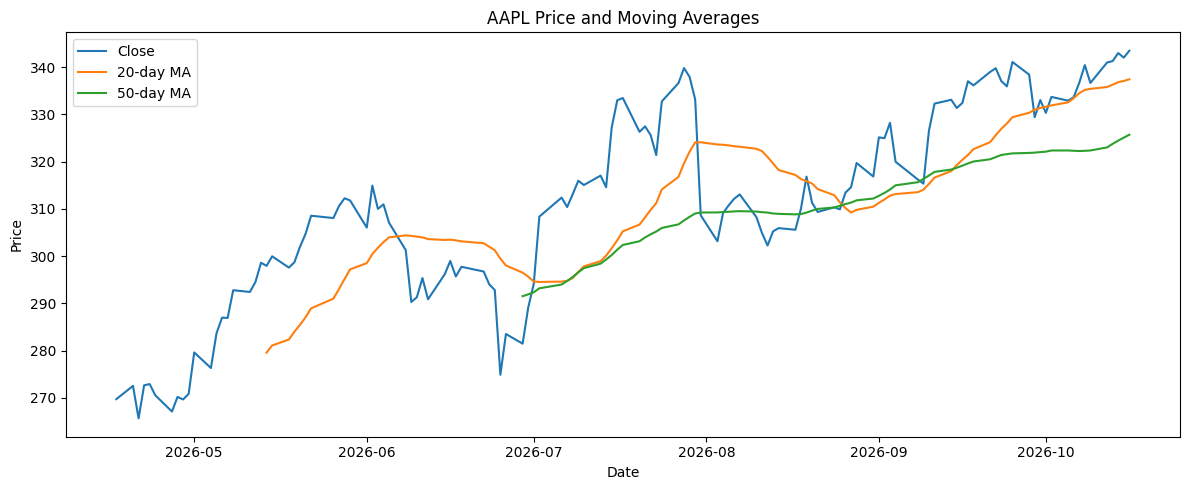

In [9]:

if not history.empty:
    chart = history.copy()
    chart["MA20"] = chart["Close"].rolling(20).mean()
    chart["MA50"] = chart["Close"].rolling(50).mean()

    plt.figure(figsize=(12, 5))
    plt.plot(chart.index, chart["Close"], label="Close")
    plt.plot(chart.index, chart["MA20"], label="20-day MA")
    plt.plot(chart.index, chart["MA50"], label="50-day MA")
    plt.title(f"{TICKER} Price and Moving Averages")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No market history returned.")


### Visualization — Interpretation

The chart makes the market trend easier to inspect than a text-only output. It also satisfies the project's requirement to include relevant visualizations demonstrating the agent workflows and functions.


## 10. Evidence-Grounded Investment Synthesis

The specialist outputs are combined into an integrated research report.

The synthesis separates:

- **Market evidence**
- **Company/financial evidence**
- **News evidence**
- **Interpretation**
- **Risk**
- **Limitations**
- **Memory context**

This structure is important because the system should distinguish observed evidence from interpretation.


In [10]:

def build_integrated_analysis(ticker, market, financials, news_summary, memory):
    company = financials.get("longName") or ticker
    sector = financials.get("sector") or "Unavailable"
    pe = financials.get("trailingPE")
    margin = financials.get("profitMargins")

    previous = [m for m in memory if m.get("ticker") == ticker]
    memory_context = (
        f"Previous run exists: {previous[-1]}"
        if previous else
        "No previous run for this ticker was found in memory."
    )

    period_return = market.get("period_return_pct")
    volatility = market.get("annualized_volatility_pct")

    text = f'''
Investment Research Summary — {company} ({ticker})

MARKET EVIDENCE
- Latest available price: {market.get("latest_price")}
- Return over selected period: {period_return:.2f}%
- Trend signal based on the 20-day moving average: {market.get("trend_signal")}
- Annualized historical volatility: {volatility:.2f}%

COMPANY EVIDENCE
- Sector: {sector}
- Trailing P/E: {pe}
- Profit margin: {margin}

NEWS EVIDENCE
{news_summary}

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, incomplete information,
and the possibility that news sentiment does not reflect longer-term business performance.

MEMORY
{memory_context}

LIMITATIONS
This analysis uses publicly available data retrieved through selected tools. Data may be
missing, delayed, or inconsistent across sources. The output is a research aid and not
personalized financial advice.
'''.strip()

    return text


memory = load_memory()

integrated_text = build_integrated_analysis(
    TICKER, market_result, financial_result, news_summary, memory
)

analysis = {
    "ticker": TICKER,
    "market": market_result,
    "financials": financial_result,
    "news_summary": news_summary,
    "news_is_live": news_is_live,
    "integrated_analysis": integrated_text,
}

print(integrated_text)


Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
ILLUSTRATIVE SAMPLE ARTICLES — NOT LIVE NEWS; excluded from evidence scoring.
- Illustrative example: AAPL quarterly revenue and earnings guidance (Synthetic teaching example)
- Illustrative example: AAPL shares and market price movement (Synthetic teaching example)
- Illustrative example: AAPL product launch and strategic partnership (Synthetic teaching example)

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks in

### Integrated Analysis — Interpretation

The resulting report combines the independent evidence streams into one research narrative. The risk and limitation sections prevent the system from presenting financial predictions as certain conclusions.


## 11. Agent Function — Self-Reflection

The evaluator checks whether the generated analysis contains the expected evidence and responsible caveats.

The evaluation considers:

- market evidence
- financial evidence
- news evidence
- risk discussion
- uncertainty/limitations

This demonstrates the required **self-reflection** capability.


In [11]:

evaluator = EvaluatorAgent("Evaluator")
evaluation = evaluator.evaluate(analysis)
analysis["evaluation"] = evaluation

print("Evaluation score:", round(evaluation["score"], 2))

display(pd.DataFrame([
    {"criterion": k, "passed": v}
    for k, v in evaluation["checks"].items()
]))

print("\nFeedback:")
for item in evaluation["feedback"]:
    print("-", item)


[Evaluator] Evaluating analysis quality
Evaluation score: 80.0


,criterion,passed
0,has_market_data,True
1,has_financial_data,True
2,has_news_evidence,False
3,has_risk_discussion,True
4,has_uncertainty,True



Feedback:
- Add recent news evidence.


### Self-Reflection — Interpretation

The evaluator converts qualitative requirements into explicit checks and produces a score plus feedback. This makes self-reflection observable and measurable instead of simply claiming that the agent reviewed its own work.


## 12. Workflow Pattern 3 — Evaluator–Optimizer

The evaluator's feedback is passed to an Optimizer Agent.

The workflow is:

```text
Initial Analysis
      ↓
Evaluator
      ↓
Feedback
      ↓
Optimizer
      ↓
Improved Analysis
      ↓
Evaluation Again
```

This demonstrates iterative improvement.


In [12]:

optimizer = OptimizerAgent("Optimizer")

before_score = evaluation["score"]
analysis = optimizer.optimize(analysis, evaluation)

after_evaluation = evaluator.evaluate({
    **analysis,
    "integrated_analysis": analysis["optimized_analysis"],
})

analysis["evaluation_after_optimization"] = after_evaluation

print("Score before optimization:", round(before_score, 2))
print("Score after optimization:", round(after_evaluation["score"], 2))

print("\nOPTIMIZED ANALYSIS\n")
print(analysis["optimized_analysis"])


[Optimizer] Refining analysis using evaluator feedback
[Evaluator] Evaluating analysis quality
Score before optimization: 80.0
Score after optimization: 80.0

OPTIMIZED ANALYSIS

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
ILLUSTRATIVE SAMPLE ARTICLES — NOT LIVE NEWS; excluded from evidence scoring.
- Illustrative example: AAPL quarterly revenue and earnings guidance (Synthetic teaching example)
- Illustrative example: AAPL shares and market price movement (Synthetic teaching example)
- Illustrative example: AAPL product launch and strategic partnership (Synthetic teaching example)

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent 

### Evaluator–Optimizer — Interpretation

The notebook compares the evaluation before and after optimization. The optimizer adds or improves risk and limitation statements when the evaluator identifies gaps.

This directly demonstrates the third required workflow pattern.


## 13. Agent Function — Learning Across Runs

After optimization, the system stores a memory record containing information about the run.

The goal is not to retrain the Gemini model. Instead, the agent system retains useful observations externally and can use them as context during future runs.


In [13]:

memory_note = update_memory(TICKER, analysis)

print("Saved memory note:")
display(pd.DataFrame([memory_note]))

print("\nRecent memory:")
display(pd.DataFrame(load_memory()).tail(10))


Saved memory note:


,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,lesson
0,2026-10-18T18:25:53.223890+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.



Recent memory:


,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,lesson,llm_enabled
0,2026-10-17T14:11:04.976264+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
1,2026-10-17T14:11:41.189857+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,True
2,2026-10-17T14:16:35.059286+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
3,2026-10-17T14:16:35.636573+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
4,2026-10-17T14:17:05.664247+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,True
5,2026-10-17T14:17:58.011440+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
6,2026-10-17T14:17:58.671846+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
7,2026-10-17T14:18:34.426408+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,True
8,2026-10-18T18:24:23.705693+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN
9,2026-10-18T18:25:53.223890+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN


### Persistent Memory — Interpretation

The displayed memory record provides concrete evidence that information from the current run has been saved for future use.


## 14. End-to-End Autonomous Workflow

The following function combines the individual components into one repeatable workflow.

It performs:

1. Planning
2. Market-data retrieval
3. Financial-data retrieval
4. News ingestion and preprocessing
5. Routing
6. Integrated analysis
7. Evaluation
8. Optimization
9. Final evaluation
10. Memory update


In [14]:
def run_investment_research(ticker):
    manager = ResearchManagerAgent("Research Manager")
    market_agent = MarketSpecialistAgent("Market Specialist")
    earnings_agent = EarningsSpecialistAgent("Earnings Specialist")
    news_agent = NewsSpecialistAgent("News Specialist")
    router = RouterAgent("Router")

    evaluator = EvaluatorAgent("Evaluator")
    optimizer = OptimizerAgent("Optimizer")

    # Step 1: Create the research plan
    plan = manager.plan(ticker)

    # Step 2: Route market analysis to the Market Specialist
    history = yf.Ticker(ticker).history(
        period=PERIOD,
        auto_adjust=True
    )

    market = router.dispatch(
        "market", history,
        market_agent, earnings_agent, news_agent
    )

    # Step 3: Route financial analysis to the Earnings Specialist
    financials = router.dispatch(
        "earnings", ticker,
        market_agent, earnings_agent, news_agent
    )

    # Step 4: Collect news and route it through the News Specialist
    raw_news = news_agent.ingest(ticker)
    news_is_live = not raw_news.empty
    if news_is_live:
        news_input = raw_news
    else:
        print("[Research Manager] No live news returned; routing labelled hypothetical examples only.")
        news_input = illustrative_news_examples(ticker)

    news_result = router.dispatch(
        "news", news_input,
        market_agent, earnings_agent, news_agent
    )

    clean_news = news_result["articles"]
    summary = news_result["summary"]
    news_is_live = bool(news_is_live and news_result.get("news_is_live", False))

    # Step 5: Router has already delegated each article and attached specialist output.
    if not clean_news.empty:
        display_columns = [c for c in ["title", "category", "routed_to", "specialist_analysis"] if c in clean_news.columns]
        print("\nArticle-level specialist delegation:")
        display(clean_news[display_columns].head(10))

    # Step 6: Integrate the findings with persistent memory
    memory = load_memory()

    integrated = build_integrated_analysis(
        ticker, market, financials, summary, memory
    )

    result = {
        "ticker": ticker,
        "plan": plan,
        "market": market,
        "financials": financials,
        "news": clean_news,
        "news_summary": summary,
        "news_is_live": news_is_live,
        "integrated_analysis": integrated,
    }

    # Step 7: Evaluate the initial analysis
    first_eval = evaluator.evaluate(result)
    result["evaluation"] = first_eval

    # Step 8: Improve the analysis using evaluator feedback
    result = optimizer.optimize(result, first_eval)

    # Step 9: Evaluate the optimized analysis
    final_eval = evaluator.evaluate({
        **result,
        "integrated_analysis": result["optimized_analysis"],
    })

    result["final_evaluation"] = final_eval

    # Step 10: Save learning for future runs
    update_memory(ticker, result)

    return result


# Execute the complete workflow
final_result = run_investment_research(TICKER)

print(
    "FINAL EVALUATION SCORE:",
    round(final_result["final_evaluation"]["score"], 2)
)

print("\nFINAL ANALYSIS\n")
print(final_result["optimized_analysis"])


[Research Manager] Creating research plan for AAPL
[Router] Delegating 'market' task
[Market Specialist] Analyzing market data
[Router] Delegating 'earnings' task
[Earnings Specialist] Analyzing company financial information
[News Specialist] Collecting recent news
[Research Manager] No live news returned; routing labelled hypothetical examples only.
[Router] Delegating 'news' task
[News Specialist] Preprocessing news
[Router] Routing article 'Illustrative example: AAPL quarterly revenue and earnings guidance' -> Earnings Specialist
[Router] Routing article 'Illustrative example: AAPL shares and market price movement' -> Market Specialist
[Router] Routing article 'Illustrative example: AAPL product launch and strategic partnership' -> News Specialist
[News Specialist] Summarizing news

Article-level specialist delegation:


,title,category,routed_to,specialist_analysis
0,Illustrative example: AAPL quarterly revenue and earnings guidance,earnings,Earnings Specialist,Earnings Specialist reviewed: Illustrative example: AAPL quarterly revenue and earnings guidance. Relevant indicator...
1,Illustrative example: AAPL shares and market price movement,market,Market Specialist,Market Specialist reviewed: Illustrative example: AAPL shares and market price movement. Treat the article as qualit...
2,Illustrative example: AAPL product launch and strategic partnership,news,News Specialist,News Specialist reviewed: Illustrative example: AAPL product launch and strategic partnership. Preliminary keyword-b...


[Evaluator] Evaluating analysis quality
[Optimizer] Refining analysis using evaluator feedback
[Evaluator] Evaluating analysis quality
FINAL EVALUATION SCORE: 80.0

FINAL ANALYSIS

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
ILLUSTRATIVE SAMPLE ARTICLES — NOT LIVE NEWS; excluded from evidence scoring.
- Illustrative example: AAPL quarterly revenue and earnings guidance (Synthetic teaching example)
- Illustrative example: AAPL shares and market price movement (Synthetic teaching example)
- Illustrative example: AAPL product launch and strategic partnership (Synthetic teaching example)

INTERPRETATION
Market evidence should be considered together with company fundamentals and recen

### End-to-End Workflow — Interpretation

This is the complete autonomous execution path. The earlier sections explained and tested the individual components; this function demonstrates how they operate together as one system.


## 15. Rubric Coverage Check

The following summary connects the implementation to the project requirements.

| Requirement | Implementation |
|---|---|
| Planning | Research Manager |
| Dynamic tool use | Yahoo Finance retrieval |
| Self-reflection | LLM + deterministic evaluators |
| Learning across runs | JSON memory |
| Prompt Chaining | News processing pipeline |
| Routing | Specialist selection |
| Evaluator–Optimizer | Evaluation and refinement loop |
| Visualization | Market price and moving-average chart |

This section is a reviewer-friendly map showing where each required capability appears in the notebook.


## 16. Gemini LLM Integration

The project uses Gemini 2.5 Flash as the natural-language reasoning layer. The API key is loaded from a local `.env` file rather than being stored in the notebook.

The implementation also keeps a deterministic fallback so that the project can continue to operate if the external LLM is unavailable.


In [15]:
# Optional LLM dependencies.
# If you do not want to use an LLM, you can skip this cell and continue with the deterministic workflow.
%pip install -q langchain-google-genai langchain-core

Note: you may need to restart the kernel to use updated packages.


In [16]:
import os
from dotenv import load_dotenv

# Load variables from .env
load_dotenv()

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY", "").strip()

LLM_MODEL = "gemini-2.5-flash"

if GOOGLE_API_KEY:
    print("GOOGLE_API_KEY detected. LLM-enhanced mode is available.")
else:
    print("No GOOGLE_API_KEY detected. Deterministic fallback mode remains available.")

GOOGLE_API_KEY detected. LLM-enhanced mode is available.


### Gemini Configuration — Explanation

The environment setup verifies that the API key exists without printing the secret. The key should remain in `.env`, and `.env` must be excluded from GitHub.


In [17]:
# LLM wrapper with a safe deterministic fallback.

class LLMResearchAgent(BaseAgent):
    def __init__(self, name="LLM Research Agent", api_key=None, model=LLM_MODEL):
        super().__init__(name)
        self.enabled = bool(api_key)
        self.model_name = model
        self.llm = None

        if self.enabled:
            try:
                from langchain_google_genai import ChatGoogleGenerativeAI

                self.llm = ChatGoogleGenerativeAI(
                    model=self.model_name,
                    google_api_key=api_key,
                    temperature=0.2,
                )

                self.log(f"LLM enabled with {self.model_name}")

            except Exception as exc:
                self.enabled = False
                self.log(f"LLM initialization failed; using fallback: {exc}")

    def generate(self, prompt, fallback):
        if not self.enabled or self.llm is None:
            return fallback

        try:
            response = self.llm.invoke(prompt)
            return response.content if hasattr(response, "content") else str(response)

        except Exception as exc:
            self.log(f"LLM call failed; using fallback: {exc}")
            return fallback


llm_agent = LLMResearchAgent(api_key=GOOGLE_API_KEY)

print(
    "LLM mode:",
    "ON" if llm_agent.enabled else "OFF / FALLBACK"
)

[LLM Research Agent] LLM enabled with gemini-2.5-flash
LLM mode: ON


### LLM Wrapper — Interpretation

The wrapper reports whether Gemini is active and provides a safe fallback path. When Gemini is available, the same agent workflow can use LLM-generated planning and reasoning; otherwise, deterministic outputs remain available.


## 17. LLM-Based Planning

The Research Manager can use Gemini to turn the research context into a structured plan. This strengthens the planning requirement by making the plan generated through an actual LLM rather than only hard-coded Python steps.


In [18]:
plan_context = f"""
Ticker: {TICKER}
Available workflow: market data, company financials, recent news, routing, evaluation, optimization, memory.
Previous memory: {json.dumps(load_memory()[-3:], indent=2)}
"""

fallback_plan_text = """
1. Validate market price history and calculate return/volatility/trend.
2. Inspect company fundamentals and valuation indicators.
3. Review recent news and classify articles by earnings, market, or general news.
4. Route evidence to the relevant specialist.
5. Synthesize evidence while separating facts from interpretation.
6. Evaluate the draft for completeness, risks, uncertainty, and unsupported claims.
7. Refine the draft and store a concise memory note.
""".strip()

planning_prompt = f"""
You are the planning component of a multi-agent financial research system.
Create a concise 7-step research plan for {TICKER}.
Use only the tools actually available: Yahoo Finance market data, company information,
news retrieval, specialist routing, evaluator, optimizer, and persistent memory.
Do not invent unavailable data sources.

Context:
{plan_context}
"""

llm_plan = llm_agent.generate(planning_prompt, fallback_plan_text)
print(llm_plan)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Here is a concise 7-step research plan for AAPL:

1.  **Retrieve Core Data:** Use Yahoo Finance market data and company information to gather current and historical stock prices, trading volumes, and key financial statements (income, balance sheet, cash flow).
2.  **Gather Recent News:** Use news retrieval to collect the latest relevant news, press releases, and analyst reports concerning AAPL.
3.  **Contextualize with Memory:** Access persistent memory to compare current market trends and initial data points with previous AAPL trend signals, period returns, and evaluation scores.
4.  **Route for Specialist Analysis:** Based on initial data and news, use specialist routing to analyze specific areas such as competitive landscape, product pipeline, or valuation metrics.
5.  **Synthesize & Evaluate:** Use the evaluator to combine market data, company financials, news, specialist insights, and historical context into a comprehensive assessment of AAPL's current standing and potential.
6.  

### LLM Planning — Interpretation

The generated plan demonstrates the LLM's role in deciding what evidence and analysis steps are relevant to the selected company.


## 18. LLM Evidence-Grounded Synthesis

The LLM receives structured market, financial, news, and memory evidence. It is instructed to base the research report on that evidence and to include risks and limitations.

This is evidence-grounded generation because the model is given retrieved project data rather than being asked for an unsupported stock opinion.


In [19]:
market_json = json.dumps(market_result, indent=2, default=str)
financial_json = json.dumps(financial_result, indent=2, default=str)
news_text = news_summary
memory_text = json.dumps(load_memory()[-3:], indent=2, default=str)

fallback_synthesis = analysis["integrated_analysis"]

synthesis_prompt = f"""
You are the synthesis agent in a multi-agent financial research system.

Produce a concise, evidence-grounded research report for {TICKER}.
Use ONLY the evidence supplied below. Do not invent numbers, events, recommendations,
or sources. Clearly distinguish facts from interpretation. Include a risk section and
limitations. This is not personalized investment advice.

MARKET DATA:
{market_json}

FINANCIAL DATA:
{financial_json}

NEWS SUMMARY:
{news_text}

RECENT MEMORY:
{memory_text}
"""

llm_synthesis = llm_agent.generate(synthesis_prompt, fallback_synthesis)

print("LLM-ENHANCED RESEARCH REPORT\n")
print(llm_synthesis)

LLM-ENHANCED RESEARCH REPORT

**AAPL Research Report**

**Date:** [Current Date]

**1. Overview**
Apple Inc. (AAPL) operates in the Technology sector, specifically within the Consumer Electronics industry.

**2. Market Performance**

*   **Price Movement (Facts):** AAPL's start price was $269.75, and its latest price is $343.46. Over the period, the stock achieved a return of 27.33%. The stock traded within a range of $265.70 (minimum) to $343.46 (maximum).
*   **Trend & Volatility (Facts):** The 20-day moving average (MA20) is $337.42, and the 50-day moving average (MA50) is $325.69. The current trend signal is "Bullish." The annualized volatility for the period was 26.77%.
*   **Interpretation:** The significant period return and bullish trend signal, supported by the MA20 being above the MA50, indicate strong recent upward momentum for AAPL. The annualized volatility suggests a moderate level of price fluctuation.

**3. Financial Health**

*   **Valuation (Facts):** Apple Inc. has a

### LLM Synthesis — Interpretation

The generated report combines the retrieved evidence into a readable investment-research narrative while retaining explicit risk and limitation statements.


## 19. LLM Self-Reflection

Gemini is also used as a qualitative evaluator. The evaluator prompt asks the model to assess whether the report contains the required evidence, risks, limitations, and appropriate uncertainty.

This complements the deterministic evaluator used earlier.


In [20]:
llm_eval_prompt = f"""
Evaluate the following financial research report using five criteria, each scored 0 or 1:
1. Market evidence is present.
2. Financial/company evidence is present.
3. News evidence is present.
4. Risks are discussed.
5. Uncertainty/limitations are explicitly stated.

Return exactly:
SCORE: <0-5>
FEEDBACK: <short semicolon-separated feedback>

REPORT:
{llm_synthesis}
"""

llm_eval_fallback = (
    f"SCORE: {int(round(evaluation['score'] / 20))}\n"
    f"FEEDBACK: {('; '.join(evaluation['feedback']) if evaluation['feedback'] else 'All core criteria passed.')}"
)

llm_evaluation_text = llm_agent.generate(llm_eval_prompt, llm_eval_fallback)
print(llm_evaluation_text)

SCORE: 4
FEEDBACK: News evidence is missing; market and financial evidence are present; risks are discussed; limitations are explicitly stated.


### LLM Self-Reflection — Interpretation

The LLM evaluator provides a human-readable score and feedback. This demonstrates that the system can critique its own generated analysis before finalization.


## 20. LLM Evaluator–Optimizer

The optimizer receives the evaluator's feedback and is instructed to revise the research report.

This creates the complete LLM-based iterative loop:

```text
Gemini Report → Gemini Evaluation → Feedback → Gemini Optimization
```


In [21]:
optimizer_prompt = f"""
You are the optimizer in a multi-agent financial research system.

Revise the report using the evaluator feedback below.
Preserve all supported financial facts. Do not invent missing information.
Make the result concise, evidence-grounded, transparent about uncertainty, and explicit about risk.
Do not provide personalized investment advice.

EVALUATOR FEEDBACK:
{llm_evaluation_text}

ORIGINAL REPORT:
{llm_synthesis}
"""

optimized_fallback = analysis.get("optimized_analysis", llm_synthesis)
llm_optimized = llm_agent.generate(optimizer_prompt, optimized_fallback)

print("OPTIMIZED REPORT\n")
print(llm_optimized)

OPTIMIZED REPORT

**AAPL Research Report**

**Date:** [Current Date]

**1. Overview**
Apple Inc. (AAPL) operates in the Technology sector, specifically within the Consumer Electronics industry.

**2. Market Performance**

*   **Price Movement:** AAPL's start price was $269.75, and its latest price is $343.46, yielding a 27.33% return over the period. The stock traded between $265.70 (minimum) and $343.46 (maximum).
*   **Trend & Volatility:** The 20-day moving average (MA20) is $337.42, above the 50-day moving average (MA50) of $325.69, indicating a "Bullish" trend signal. Annualized volatility for the period was 26.77%.
*   **Interpretation:** The significant period return and bullish trend signal (MA20 > MA50) suggest strong recent upward momentum. The 26.77% annualized volatility indicates a moderate level of price fluctuation.

**3. Financial Health**

*   **Valuation:** Apple Inc. has a market capitalization of $5.01 trillion. Its trailing P/E ratio is 39.39, and its forward P/E r

### LLM Optimization — Interpretation

The optimizer produces a refined version of the research report using the evaluator's feedback. This is the LLM implementation of the required Evaluator–Optimizer workflow.


## 21. Final Dual Evaluation

The optimized report is evaluated again. Using both LLM and deterministic checks gives the project two complementary forms of validation.

The LLM evaluator focuses on qualitative research quality, while the deterministic evaluator checks explicit evidence requirements.


In [22]:
final_analysis_for_eval = {
    "market": market_result,
    "financials": financial_result,
    "news_summary": final_result.get("news_summary", news_summary),
    "news_is_live": bool(final_result.get("news_is_live", news_is_live)),
    "integrated_analysis": llm_optimized,
}

deterministic_final = evaluator.evaluate(final_analysis_for_eval)

comparison = pd.DataFrame([
    {"Evaluator": "Deterministic", "Score": deterministic_final["score"]},
    {"Evaluator": "LLM", "Score": None if not llm_agent.enabled else "Qualitative"},
])

display(comparison)
print("\nDeterministic final score:", round(deterministic_final["score"], 2))
print("LLM mode:", "Enabled" if llm_agent.enabled else "Fallback")

[Evaluator] Evaluating analysis quality


,Evaluator,Score
0,Deterministic,80.0
1,LLM,Qualitative



Deterministic final score: 80.0
LLM mode: Enabled


### Final Evaluation — Interpretation

The final evaluation provides evidence that the system did not stop after the first generated report. It completed an explicit evaluation-and-improvement cycle.


## 22. Improved Learning Across Runs

The final LLM-enhanced result is stored in persistent memory. This extends the original memory mechanism so later executions can retain information from the completed agentic workflow.


In [23]:
final_memory_record = {
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "ticker": TICKER,
    "trend_signal": market_result.get("trend_signal"),
    "period_return_pct": market_result.get("period_return_pct"),
    "evaluation_score": deterministic_final.get("score"),
    "llm_enabled": llm_agent.enabled,
    "lesson": "Use prior trend/evaluation context when planning the next research run."
}

memory = load_memory()
memory.append(final_memory_record)
save_memory(memory)

display(pd.DataFrame(load_memory()).tail(10))

,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,lesson,llm_enabled
0,2026-10-17T14:16:35.059286+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
1,2026-10-17T14:16:35.636573+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
2,2026-10-17T14:17:05.664247+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,True
3,2026-10-17T14:17:58.011440+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
4,2026-10-17T14:17:58.671846+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
5,2026-10-17T14:18:34.426408+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,True
6,2026-10-18T18:24:23.705693+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN
7,2026-10-18T18:25:53.223890+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN
8,2026-10-18T18:25:53.768206+00:00,AAPL,Bullish,27.325946,80.0,Compare future runs with previous market trend and evaluation score.,NaN
9,2026-10-18T18:26:23.568205+00:00,AAPL,Bullish,27.325946,80.0,Use prior trend/evaluation context when planning the next research run.,True


### Improved Memory — Interpretation

The memory record provides a persistent trace of the final run, including the ticker and evaluation information. This supports the required learning-across-runs capability.


## 23. Final Architecture

The complete system can be summarized as:

```text
                 User / Stock Symbol
                        ↓
               Research Manager
                  Gemini LLM
                        ↓
                  Router Agent
        ┌───────────────┼───────────────┐
        ↓               ↓               ↓
   Market Agent     News Agent     Earnings Agent
   (article-level specialist methods are called by the router)
        └───────────────┼───────────────┘
                        ↓
              Evidence Synthesis
                        ↓
                 LLM Evaluator
                        ↓
                  Optimizer
                        ↓
             Deterministic Check
                        ↓
                Persistent Memory
                        ↓
                 Final Report
```

This architecture demonstrates how planning, tools, specialist agents, LLM reasoning, evaluation, optimization, and memory work together.


## 24. Limitations and Responsible Use

The system is a financial-research demonstration, not personalized investment advice.

Important limitations include:

- Financial and news data can be incomplete or delayed.
- Market trends do not guarantee future returns.
- LLM-generated explanations can contain errors.
- Evaluation scores are indicators of output quality, not proof of factual correctness.
- Persistent memory is lightweight JSON storage rather than a production-grade memory service.

These limitations are intentionally included so the system does not present generated financial analysis as certainty.


- If live news retrieval returns no articles, clearly labelled hypothetical examples may be used to demonstrate routing mechanics. They are excluded from live-news evidence scoring and must not be interpreted as actual company news.


## 25. AI-Assistance Disclosure

AI-assisted tools were used during development to support code organization, debugging, explanation, and documentation. Gemini 2.5 Flash is also an intentional component of the implemented system for planning, synthesis, evaluation, and optimization.


# References

Google. (2026). *Gemini API documentation*. Google AI for Developers. https://ai.google.dev/gemini-api/docs

LangChain. (2026). *LangChain documentation*. https://python.langchain.com/docs/

Matplotlib Development Team. (2026). *Matplotlib documentation*. https://matplotlib.org/stable/

NumPy Developers. (2026). *NumPy documentation*. https://numpy.org/doc/

Pandas Development Team. (2026). *Pandas documentation*. https://pandas.pydata.org/docs/

scikit-learn developers. (2026). *Scikit-learn: Machine learning in Python*. https://scikit-learn.org/stable/

Yahoo Finance. (2026). *Yahoo Finance*. https://finance.yahoo.com/

yfinance developers. (2026). *yfinance documentation*. https://ranaroussi.github.io/yfinance/

University of San Diego. (2026). *Final Team Project: Multi-Agent Financial Analysis System*. AAI-335 course assignment materials.